# Transformer. Seminar 2. Сборка мини-трансформера

На прошлом семинаре разобрали одну операцию: scaled dot-product attention, маски и готовые классы головы и блока.

Сегодня эти классы пишем сами и собираем из них маленькую модель. Смотрим не на качество перевода, а на то, как один и тот же тензор выглядит на разных уровнях.

Порядок:

0. открываем маленький настоящий BERT и смотрим те же блоки вживую;

1. разрезаем вектор на головы;
2. multi-head attention;
3. feed-forward, остаток, LayerNorm;
4. один блок энкодера;
5. эмбеддинг, позиция и стек из двух блоков;
6. одно предложение прогоняем по уровням;
7. тот же блок внимания, но cross-attention.

Свою модель не обучаем: у неё веса случайные. BERT ниже уже обучен, но карту всё равно не читаем как смысл. Смотрим формы, сумму весов в строке и нули на `<pad>`.

## 0. Зависимости

In [1]:
import math
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(".mplconfig").resolve()))
os.environ.setdefault("HF_HOME", str(Path(".hf_cache").resolve()))

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
torch.set_num_threads(min(2, os.cpu_count() or 1))

print("torch:", torch.__version__)
print("device: cpu")

torch: 2.8.0
device: cpu


## 1. Attention с прошлого раза

Ниже тот же `scaled_dot_product_attention`. `mask=True` значит «смотреть можно».

Формула не меняется:

$$
\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

In [2]:
def stable_softmax(x, dim=-1):
    x_shifted = x - x.max(dim=dim, keepdim=True).values
    exp_x = torch.exp(x_shifted)
    return exp_x / exp_x.sum(dim=dim, keepdim=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    # Q: [..., n_queries, d_k]
    # K: [..., n_keys, d_k]
    # V: [..., n_keys, d_v]
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
    weights = stable_softmax(scores, dim=-1)
    return weights @ V, weights


def plot_attention(weights, x_labels=None, y_labels=None, title="Attention", ax=None):
    if weights.dim() == 3:
        weights = weights[0]
    weights = weights.detach().cpu()

    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))

    im = ax.imshow(weights, cmap="viridis", vmin=0.0, vmax=1.0)
    ax.set_title(title)
    ax.set_xlabel("keys")
    ax.set_ylabel("queries")
    if x_labels is not None:
        ax.set_xticks(range(len(x_labels)))
        ax.set_xticklabels(x_labels, rotation=35, ha="right")
    if y_labels is not None:
        ax.set_yticks(range(len(y_labels)))
        ax.set_yticklabels(y_labels)
    for i in range(weights.size(0)):
        for j in range(weights.size(1)):
            ax.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return ax

## 2. Что внутри настоящего BERT

Дальше соберём те же куски руками на тензоре длины 8. Сначала посмотрим, как они называются в настоящей модели.

Берём `bert-tiny`, веса лежат в `models/bert-tiny`, интернет не нужен. Это BERT: те же эмбеддинги, внимание, FFN и Add & Norm. Слоёв два, а не двенадцать, размер вектора 128, а не 768. У обычного BERT-base блоков больше и они шире, картина та же: 12 слоёв, `d_model = 768`, 12 голов, около 110 миллионов параметров.

Печатаем имена и размеры матриц. Сами числа весов не печатаем: их миллионы, глазами их не читают.

In [3]:
from transformers import BertModel, BertTokenizer

bert_name = "models/bert-tiny"
tokenizer = BertTokenizer.from_pretrained(bert_name, local_files_only=True)
bert = BertModel.from_pretrained(bert_name, local_files_only=True, output_attentions=True)
bert.eval()

def nparams(module):
    return sum(p.numel() for p in module.parameters())

/Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [61]:
tokenizer.model_max_length = 32

In [76]:
input = tokenizer(
    ["мама мыла раму",
    "какой-то текст"],
    padding=True,
    return_tensors="pt"
)

In [77]:
input['input_ids']

tensor([[  101,  1191, 10260, 29745, 10260,  1191, 29113, 29436, 10260,  1195,
         10260, 29745, 29748,   102,     0],
        [  101,  1189, 10260, 23925, 14150, 10325,  1011,  1197, 14150,  1197,
         15290, 23925, 29747, 22919,   102]])

In [78]:
input['attention_mask']

tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

In [64]:
tokenizer.encode("мама мыла раму [SEP] пока папа смотрел")

[101,
 1191,
 10260,
 29745,
 10260,
 1191,
 29113,
 29436,
 10260,
 1195,
 10260,
 29745,
 29748,
 102,
 1194,
 14150,
 28598,
 1194,
 10260,
 29746,
 10260,
 1196,
 29745,
 14150,
 22919,
 16856,
 15290,
 29436,
 102]

In [62]:
tokenizer

BertTokenizer(name_or_path='models/bert-tiny', vocab_size=30522, model_max_length=32, is_fast=False, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, clean_up_tokenization_spaces=True, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}
)

In [5]:
nparams(bert)

4385920

In [4]:
bert

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 128, padding_idx=0)
    (position_embeddings): Embedding(512, 128)
    (token_type_embeddings): Embedding(2, 128)
    (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-1): 2 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=128, out_features=128, bias=True)
            (key): Linear(in_features=128, out_features=128, bias=True)
            (value): Linear(in_features=128, out_features=128, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=128, out_features=128, bias=True)
            (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
    

In [6]:
print("слоёв:       ", bert.config.num_hidden_layers)
print("d_model:     ", bert.config.hidden_size)
print("голов:       ", bert.config.num_attention_heads)
print("d_head:      ", bert.config.hidden_size // bert.config.num_attention_heads)
print("d_ff:        ", bert.config.intermediate_size)
print("словарь:     ", bert.config.vocab_size)
print("параметров:  ", nparams(bert))
print("из них слова:", nparams(bert.embeddings.word_embeddings))
print("позиции:     ", nparams(bert.embeddings.position_embeddings))

print("\nодин слой, второй такой же по форме")
layer = bert.encoder.layer[0]
for name, p in layer.named_parameters():
    print(f"{name:42} {str(tuple(p.shape)):16} {p.numel()}")

слоёв:        2
d_model:      128
голов:        2
d_head:       64
d_ff:         512
словарь:      30522
параметров:   4385920
из них слова: 3906816
позиции:      65536

один слой, второй такой же по форме
attention.self.query.weight                (128, 128)       16384
attention.self.query.bias                  (128,)           128
attention.self.key.weight                  (128, 128)       16384
attention.self.key.bias                    (128,)           128
attention.self.value.weight                (128, 128)       16384
attention.self.value.bias                  (128,)           128
attention.output.dense.weight              (128, 128)       16384
attention.output.dense.bias                (128,)           128
attention.output.LayerNorm.weight          (128,)           128
attention.output.LayerNorm.bias            (128,)           128
intermediate.dense.weight                  (512, 128)       65536
intermediate.dense.bias                    (512,)           512
output.dense.wei

`query`, `key`, `value` — это `W_q`, `W_k`, `W_v`, каждая размера `d_model × d_model`. Потом вектор режется на 2 головы по 64. `attention.output.dense` — склейка, наш `W_o`, и сразу LayerNorm. `intermediate` и `output` — две матрицы FFN, 128 → 512 → 128, и второй LayerNorm.

Таблица слов больше всех блоков внимания вместе. В большом BERT так же: основную массу параметров занимает словарь.

Маска в библиотеке — это `attention_mask`: `1` значит «смотреть можно», `0` значит `<pad>`. То же соглашение, что у нас `True` / `False`. Возьмём два предложения разной длины, короткое добьётся `[PAD]`.

токены:
  ['[CLS]', 'the', 'cat', 'sat', '[SEP]']
  ['[CLS]', 'cat', '[SEP]', '[PAD]', '[PAD]']
attention_mask:
tensor([[1, 1, 1, 1, 1],
        [1, 1, 1, 0, 0]])
веса слоя 0: (2, 2, 5, 5)
сумма строки: [1.0, 1.0, 1.0, 1.0, 1.0]


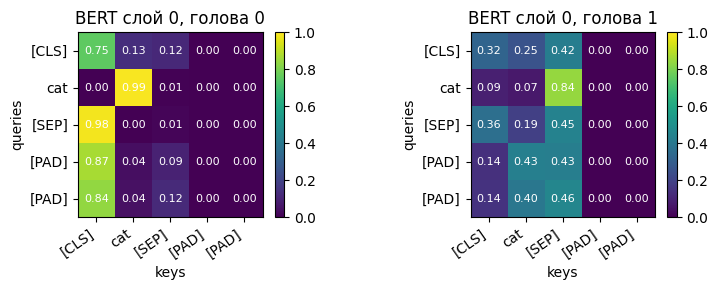

In [7]:
texts = ["the cat sat", "cat"]
batch = tokenizer(texts, return_tensors="pt", padding=True)
tokens_batch = [tokenizer.convert_ids_to_tokens(row) for row in batch["input_ids"]]

print("токены:")
for row in tokens_batch:
    print(" ", row)
print("attention_mask:")
print(batch["attention_mask"])

with torch.no_grad():
    bert_out = bert(**batch)

weights = bert_out.attentions[0]  # слой 0
print("веса слоя 0:", tuple(weights.shape))  # batch, heads, query, key
print("сумма строки:", weights[1, 0].sum(-1).round(decimals=3).tolist())

labels = tokens_batch[1]
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for head in range(2):
    plot_attention(weights[1, head], labels, labels, title=f"BERT слой 0, голова {head}", ax=axes[head])
plt.tight_layout()
plt.show()

## 3. Из чего состоит блок

В статье энкодер — это несколько одинаковых блоков. Один блок:

```
x
 → multi-head attention
 → LayerNorm(x + attention)      Add & Norm
 → feed-forward
 → LayerNorm(x + feed-forward)   Add & Norm
 → x'
```

На входе и на выходе тензор одной формы: `[batch, seq, d_model]`. Длина предложения не меняется. Меняются числа внутри векторов.

Чтобы всё помещалось на экране, берём маленькие размеры. В статье `d_model = 512` и 8 голов. Формулы те же.

Предложение на сегодня: **мама мыла раму**.

Один блок энкодера из лекции. `Nx` значит «таких блоков несколько подряд».

<img src="docs/figures/encoder_block.png" alt="Блок энкодера" width="280">


In [8]:
d_model = 8
n_heads = 2
d_head = d_model // n_heads  # 4
d_ff = 16

vocab = {"<pad>": 0, "мама": 1, "мыла": 2, "раму": 3}
id_to_token = {i: w for w, i in vocab.items()}

ids = torch.tensor([[1, 2, 3]])  # мама мыла раму
tokens = [id_to_token[i] for i in ids[0].tolist()]
print(tokens, tuple(ids.shape))
print("d_model", d_model, "heads", n_heads, "d_head", d_head)

['мама', 'мыла', 'раму'] (1, 3)
d_model 8 heads 2 d_head 4


## 4. Режем вектор на головы

У каждого токена один вектор длины `d_model`. Головы не делают новые векторы из воздуха: они делят этот вектор на равные куски.

8 чисел токена при двух головах: первые 4 — голова 0, вторые 4 — голова 1.

После `view` оси такие: `[batch, seq, heads, d_head]`. Attention с прошлого раза ждёт, что «пакетная» ось идёт раньше длины. Поэтому `transpose`: `[batch, heads, seq, d_head]`.

[batch, seq, d_model] -> [batch, heads, seq, d_head]

In [ ]:
# d_model / n_heads = d_head

In [9]:
x = torch.arange(24).float().view(1, 3, 8)
print("токен 0:", x[0, 0].tolist())

parts = x.view(1, 3, 2, 4).transpose(1, 2)
print("голова 0:", parts[0, 0, 0].tolist())
print("голова 1:", parts[0, 1, 0].tolist())
print("форма голов:", tuple(parts.shape))

токен 0: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
голова 0: [0.0, 1.0, 2.0, 3.0]
голова 1: [4.0, 5.0, 6.0, 7.0]
форма голов: (1, 2, 3, 4)


Склейка — обратный `view`. Её не пишем: тут только порядок осей, не идея внимания.

Ниже проверка, что разрезали и собрали тот же тензор.


In [ ]:
def split_heads(x, n_heads):
    # x: [batch, seq, d_model] -> [batch, n_heads, seq, d_head]
    b, s, d = x.shape
    assert d % n_heads == 0, f"d_model={d} не делится на n_heads={n_heads}"
    d_head = d // n_heads
    x = x.view(b, s, n_heads, d_head)
    return x.transpose(1, 2)


def merge_heads(x):
    # x: [batch, n_heads, seq, d_head] -> [batch, seq, d_model] -> d_model = n_heads * d_head
    b, h, s, d = x.shape
    x = x.transpose(1, 2).contiguous()
    return x.view(b, s, h * d)


back = merge_heads(split_heads(x, 2))
print("склеилось обратно:", torch.equal(back, x))


склеилось обратно: True


## 5. Multi-head attention

Три проекции, как на прошлом семинаре:

$$
Q = X W_Q, \quad K = X W_K, \quad V = X W_V
$$

Дальше режем на головы, считаем attention по каждой, склеиваем и пропускаем через `W_o`. `W_o` нужен, чтобы головы перемешались между собой, а не остались четырьмя отдельными кусками.

`context=None` — self-attention: Q, K и V из одного `x`. Позже в `context` положим выход энкодера, это будет cross-attention.

Слева одна голова, её мы уже писали. Справа несколько таких голов параллельно, потом склейка и ещё один линейный слой. Это `W_o`.

<img src="docs/figures/multihead.png" alt="Multi-head attention" width="640">


### Задание. Допиши forward

Строка `Q` уже есть. Напиши `K` и `V` по тому же шаблону.


In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model должен делиться на n_heads")
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, mask=None, context=None, need_weights=False):
        # просто x везде если это у нас self-attention
        kv = x if context is None else context

        Q = split_heads(self.W_q(x), self.n_heads)
        K = split_heads(self.W_k(kv), self.n_heads)
        V = split_heads(self.W_v(kv), self.n_heads)

        # [batch, seq, seq] -> [batch, 1, seq, seq], чтобы маска легла на все головы
        if mask is not None:
            mask = mask[:, None, :, :]

        out, weights = scaled_dot_product_attention(Q, K, V, mask=mask)
        out = self.W_o(merge_heads(out))

        if need_weights:
            return out, weights
        return out

### Решение

вход:  (1, 3, 8)
Q/K/V после резки: [batch, heads, seq, d_head] = (1, 2, 3, 4)
выход: (1, 3, 8)
веса: (1, 2, 3, 3)
сумма строки, голова 0: [1.0, 1.0, 1.0]


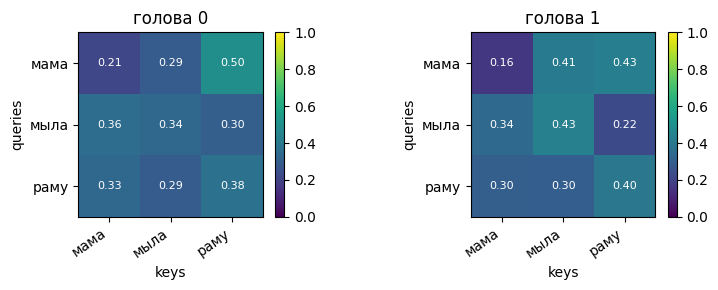

In [13]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model должен делиться на n_heads")
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, mask=None, context=None, need_weights=False):
        kv = x if context is None else context

        Q = split_heads(self.W_q(x), self.n_heads)
        K = split_heads(self.W_k(kv), self.n_heads)
        V = split_heads(self.W_v(kv), self.n_heads)

        if mask is not None:
            mask = mask[:, None, :, :]

        out, weights = scaled_dot_product_attention(Q, K, V, mask=mask)
        out = self.W_o(merge_heads(out))

        if need_weights:
            return out, weights
        return out


torch.manual_seed(SEED)
attn = MultiHeadAttention(d_model, n_heads)
x = torch.randn(1, 3, d_model)
y, w = attn(x, need_weights=True)

print("вход: ", tuple(x.shape))
print("Q/K/V после резки: [batch, heads, seq, d_head] =", (1, n_heads, 3, d_head))
print("выход:", tuple(y.shape))
print("веса:", tuple(w.shape))
print("сумма строки, голова 0:", w[0, 0].sum(-1).round(decimals=3).tolist())

fig, axes = plt.subplots(1, n_heads, figsize=(8, 3))
for head in range(n_heads):
    plot_attention(w[0, head], tokens, tokens, title=f"голова {head}", ax=axes[head])
plt.tight_layout()
plt.show()

Две карты разные: у голов разные куски `W_q`, `W_k`, `W_v`. Сумма по строке равна 1. Смысла в рисунке нет, веса ещё случайные.

Почему `d_model` обязан делиться на число голов: вектор режется на равные куски. `8 / 2 = 4`, в статье `512 / 8 = 64`. `512 / 10` не целое, такую голову `view` не соберёт.

In [14]:
torch.manual_seed(SEED)
for n in [1, 2, 4]:
    layer = MultiHeadAttention(d_model, n)
    _, weights = layer(torch.randn(1, 3, d_model), need_weights=True)
    print(f"heads={n}  d_head={layer.d_head}  weights={tuple(weights.shape)}")

heads=1  d_head=8  weights=(1, 1, 3, 3)
heads=2  d_head=4  weights=(1, 2, 3, 3)
heads=4  d_head=2  weights=(1, 4, 3, 3)


## 6. Feed-forward

После внимания стоит обычная сеть из двух линейных слоёв. Её применяют к каждому токену отдельно и с одними и теми же весами.

$$
\mathrm{FFN}(x) = \max(0, x W_1 + b_1) W_2 + b_2
$$

Attention смешивает токены между собой. FFN смешивает координаты внутри одного вектора. Соседей она не видит.

В статье внутренний слой шире модели: `512 → 2048 → 512`. У нас `8 → 16 → 8`.

In [15]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))


ff = FeedForward(d_model, d_ff)
x = torch.randn(1, 3, d_model)
y = ff(x)
y_one = ff(x[:, 1:2])  # тот же вектор, но вынутый из предложения

print("вход ", tuple(x.shape), "выход", tuple(y.shape))
print("середина совпала с отдельным вызовом:", torch.allclose(y[:, 1], y_one[:, 0]))

вход  (1, 3, 8) выход (1, 3, 8)
середина совпала с отдельным вызовом: True


## 7. Add & Norm

Вокруг attention и вокруг FFN одна и та же пара действий.

**Add.** К входу блока прибавляем выход подслоя. Вход не выкидывается. Если подслой выдаст нули, дальше пойдёт сам вход, и градиенту есть прямая дорога через сумму.

Обходная стрелка на схеме и есть остаток: вход приходит и в подслой, и сразу в сложение.

<img src="docs/figures/residual.png" alt="Residual вокруг feed-forward" width="360">


In [16]:
x = torch.tensor([1.0, 2.0, 3.0, 4.0])
delta = torch.tensor([0.1, -0.2, 0.0, 0.3])
print("вход:   ", x.tolist())
print("поправка:", delta.tolist())
print("сумма:  ", (x + delta).tolist())

вход:    [1.0, 2.0, 3.0, 4.0]
поправка: [0.10000000149011612, -0.20000000298023224, 0.0, 0.30000001192092896]
сумма:   [1.100000023841858, 1.7999999523162842, 3.0, 4.300000190734863]


**Norm.** LayerNorm считает среднее и разброс по координатам одного токена и приводит их к среднему 0 и разбросу 1. Соседние токены в этом не участвуют.

В статье записано так: `LayerNorm(x + Sublayer(x))`. Так и пишем.

Dropout из статьи (вероятность 0.1 перед сложением) сегодня не ставим. Он нужен при обучении, а мы разбираем числа: при нём они каждый запуск чуть разные.

In [17]:
nn.LayerNorm?

Init signature:
nn.LayerNorm(
    normalized_shape: Union[int, list[int], torch.Size],
    eps: float = 1e-05,
    elementwise_affine: bool = True,
    bias: bool = True,
    device=None,
    dtype=None,
) -> None
Docstring:     
Applies Layer Normalization over a mini-batch of inputs.

This layer implements the operation as described in
the paper `Layer Normalization <https://arxiv.org/abs/1607.06450>`__

.. math::
    y = \frac{x - \mathrm{E}[x]}{ \sqrt{\mathrm{Var}[x] + \epsilon}} * \gamma + \beta

The mean and standard-deviation are calculated over the last `D` dimensions, where `D`
is the dimension of :attr:`normalized_shape`. For example, if :attr:`normalized_shape`
is ``(3, 5)`` (a 2-dimensional shape), the mean and standard-deviation are computed over
the last 2 dimensions of the input (i.e. ``input.mean((-2, -1))``).
:math:`\gamma` and :math:`\beta` are learnable affine transform parameters of
:attr:`normalized_shape` if :attr:`elementwise_affine` is ``True``.
The variance is 

In [18]:
h = torch.tensor([[1.0, 2.0, 3.0, 4.0], [10.0, 10.0, 10.0, 14.0]])
norm = nn.LayerNorm(4)
out = norm(h)
print(out.round(decimals=2))
print("среднее:", out.mean(dim=-1).round(decimals=3).tolist())
print("разброс:", out.std(dim=-1, unbiased=False).round(decimals=3).tolist())

tensor([[-1.3400, -0.4500,  0.4500,  1.3400],
        [-0.5800, -0.5800, -0.5800,  1.7300]], grad_fn=<RoundBackward1>)
среднее: [0.0, 0.0]
разброс: [1.0, 1.0]


## 8. Блок энкодера

Складываем три части, которые уже есть.

### Задание. Допиши forward

Две строки: Add & Norm после attention, потом FFN и ещё раз Add & Norm.


In [ ]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None, need_weights=False):
        attn_out, weights = self.attn(x, mask=mask, need_weights=True)
        x = self.norm1(x + attn_out)
        ff_out = self.ff(x)
        x = self.norm2(x + ff_out)
        if need_weights:
            return x, weights
        return x

### Решение

In [19]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None, need_weights=False):
        attn_out, weights = self.attn(x, mask=mask, need_weights=True)
        x = self.norm1(x + attn_out)
        x = self.norm2(x + self.ff(x))
        if need_weights:
            return x, weights
        return x


torch.manual_seed(SEED)
block = EncoderBlock(d_model, n_heads, d_ff)
x = torch.randn(1, 3, d_model)
y, w = block(x, need_weights=True)
print("вход блока: ", tuple(x.shape))
print("выход блока:", tuple(y.shape))
print("веса:       ", tuple(w.shape))
print("длина та же:", x.shape == y.shape)

вход блока:  (1, 3, 8)
выход блока: (1, 3, 8)
веса:        (1, 2, 3, 3)
длина та же: True


## 9. Позиции

Если переставить токены местами и так же переставить строки, attention этого не заметит: у него нет «кто раньше». Порядок надо положить в вектор руками.

К эмбеддингу токена прибавляем вектор позиции той же длины `d_model`.

Два рабочих варианта:

- обучаемая таблица `nn.Embedding`, строка на позицию;
- синусы и косинусы из статьи, таблицу не учат.

Для сборки это одно и то же сложение. В мини-модели ниже будет таблица: её проще прочитать. Синусы показываем, потому что они в статье.

На схеме токен, его эмбеддинг и вектор позиции складываются. В мини-модели позиция из таблицы, на рисунке это синусы из статьи. Сложение то же.

<img src="docs/figures/positional.png" alt="Эмбеддинг плюс позиция" width="640">


синусы:  (16, 8)
таблица: (16, 8)
эмбеддинг + позиция: (1, 3, 8)


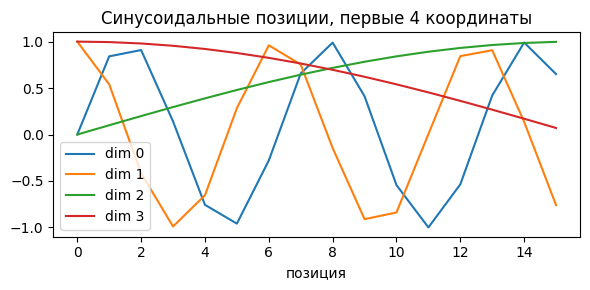

In [20]:
def sinusoidal_pe(seq_len, d_model):
    pe = torch.zeros(seq_len, d_model)
    pos = torch.arange(seq_len).unsqueeze(1)
    div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe


pe = sinusoidal_pe(16, d_model)
table = nn.Embedding(16, d_model)
print("синусы: ", tuple(pe.shape))
print("таблица:", tuple(table.weight.shape))

emb = torch.randn(1, 3, d_model)
print("эмбеддинг + позиция:", tuple((emb + pe[:3]).shape))

plt.figure(figsize=(6, 3))
for i in range(4):
    plt.plot(pe[:, i], label=f"dim {i}")
plt.xlabel("позиция")
plt.title("Синусоидальные позиции, первые 4 координаты")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Мини-модель

Модель — это не новый алгоритм. Это эмбеддинг, таблица позиций и несколько блоков подряд.

```
token ids
  → эмбеддинг + позиция
  → EncoderBlock
  → EncoderBlock
  → вектор на каждый токен
```

В статье блоков шесть. У нас два, чтобы прогон читался. Каждый следующий получает выход предыдущего, длина последовательности не меняется.

<img src="docs/figures/encoder_stack.png" alt="Стек энкодеров" width="720">


### Задание. Допиши forward

Эмбеддинг, позиция и маска уже собраны. Осталось вызвать каждый блок.


In [46]:
class MiniEncoder(nn.Module):
    def __init__(self, vocab_size, d_model=8, n_heads=2, d_ff=16, n_layers=2, max_len=16):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([
            EncoderBlock(d_model, n_heads, d_ff) for _ in range(n_layers)
        ])

    def forward(self, token_ids):
        b, s = token_ids.shape
        x = self.embed(token_ids) + self.pos(torch.arange(s))

        # строка маски копируется на каждый query: [batch, seq, seq]
        key_ok = token_ids != 0
        mask = key_ok[:, None, :].repeat(1, s, 1)

        attns = []
        for block in self.blocks:
            x, w = block(x, mask=mask, need_weights=True)
            attns.append(w)
        return x, attns

model = MiniEncoder(
    vocab_size=len(vocab),
    d_model=d_model,
    n_heads=n_heads,
    d_ff=d_ff,
    n_layers=10,
    max_len=32
)

In [47]:
sentence = "мама мама раму раму".split()

sentence = [vocab[word] for word in sentence]

sentence = torch.tensor(sentence)

sentence = sentence.unsqueeze(0)

In [48]:
model(
    sentence
)

(tensor([[[ 2.0460, -1.3459, -0.2043,  1.0616, -0.1165, -0.2427, -0.7462,
           -0.4520],
          [ 2.2717, -0.6544,  0.0916,  0.7633, -1.0030, -0.2527, -0.6794,
           -0.5371],
          [ 1.8429,  0.3937,  0.6323, -0.1695, -0.4059, -1.0011, -1.6507,
            0.3582],
          [ 1.8580, -1.3436,  0.2401,  1.0003, -0.8040, -0.0466, -1.0118,
            0.1077]]], grad_fn=<NativeLayerNormBackward0>),
 [tensor([[[[0.2972, 0.4217, 0.1111, 0.1700],
            [0.2572, 0.2655, 0.2650, 0.2122],
            [0.2793, 0.2499, 0.1920, 0.2788],
            [0.2832, 0.1746, 0.3012, 0.2410]],
  
           [[0.1399, 0.2631, 0.1833, 0.4137],
            [0.3775, 0.2963, 0.0981, 0.2280],
            [0.0601, 0.2944, 0.2951, 0.3504],
            [0.1433, 0.2047, 0.3691, 0.2829]]]], grad_fn=<DivBackward0>),
  tensor([[[[0.2570, 0.2611, 0.3067, 0.1752],
            [0.2349, 0.2143, 0.4028, 0.1479],
            [0.2346, 0.3015, 0.1573, 0.3066],
            [0.2275, 0.3411, 0.2243, 0.2071

### Решение

In [49]:
class MiniEncoder(nn.Module):
    def __init__(self, vocab_size, d_model=8, n_heads=2, d_ff=16, n_layers=2, max_len=16):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([
            EncoderBlock(d_model, n_heads, d_ff) for _ in range(n_layers)
        ])

    def forward(self, token_ids):
        b, s = token_ids.shape
        x = self.embed(token_ids) + self.pos(torch.arange(s))

        key_ok = token_ids != 0
        mask = key_ok[:, None, :].repeat(1, s, 1)

        attns = []
        for block in self.blocks:
            x, w = block(x, mask=mask, need_weights=True)
            attns.append(w)
        return x, attns


torch.manual_seed(SEED)
model = MiniEncoder(vocab_size=len(vocab), d_model=d_model, n_heads=n_heads, d_ff=d_ff, n_layers=2)
print("параметров:", sum(p.numel() for p in model.parameters()))
print("блоков:", len(model.blocks))

параметров: 1296
блоков: 2


## 11. Одно предложение по уровням

Берём `мама мыла раму` и печатаем вектор токена «мама» после каждого шага. Форма вектора всё время `d_model = 8`. Числа меняются.

Это случайная инициализация. Нам важно, что трубопровод живой: формы сходятся, строка весов суммируется в 1.

In [50]:
def show(name, t):
    mama = [round(float(v), 2) for v in t[0, 0].detach()]
    print(f"{name:22} {str(tuple(t.shape)):16} мама={mama}")


ids = torch.tensor([[vocab["мама"], vocab["мыла"], vocab["раму"]]])
tokens = ["мама", "мыла", "раму"]

# уровень 1. id токена -> вектор
x = model.embed(ids)
show("1. эмбеддинг", x)

# позиция — вектор той же длины, просто прибавляем
x = x + model.pos(torch.arange(ids.size(1)))
show("2. плюс позиция", x)

1. эмбеддинг           (1, 3, 8)        мама=[-0.75, 1.65, -0.39, -1.4, -0.73, -0.56, -0.77, 0.76]
2. плюс позиция        (1, 3, 8)        мама=[-2.14, 0.78, -0.62, 0.31, -0.41, -0.98, -0.46, -0.01]


## 12. Паддинг в собранной модели

В батче предложения разной длины добивают нулём. Нулевой эмбеддинг сам позицию не выключает, это уже разбирали. Маска, которую пишет `MiniEncoder`, ставит на столбец `<pad>` нулевой вес.

In [55]:
ids_pad = torch.tensor([
    [vocab["мама"], vocab["мыла"], vocab["раму"]],
    [vocab["мама"], vocab["мыла"], vocab["<pad>"]],
])
ids_pad

tensor([[1, 2, 3],
        [1, 2, 0]])

In [58]:
labels = ["мама", "мыла", "раму / pad"]

_, attns_pad = model(ids_pad)

attns_pad

[tensor([[[[0.2067, 0.4736, 0.3197],
           [0.3211, 0.4270, 0.2519],
           [0.2884, 0.4295, 0.2821]],
 
          [[0.3224, 0.3100, 0.3676],
           [0.2324, 0.4577, 0.3099],
           [0.3142, 0.3392, 0.3466]]],
 
 
         [[[0.3039, 0.6961, 0.0000],
           [0.4293, 0.5707, 0.0000],
           [0.7518, 0.2482, 0.0000]],
 
          [[0.5098, 0.4902, 0.0000],
           [0.3367, 0.6633, 0.0000],
           [0.6950, 0.3050, 0.0000]]]], grad_fn=<DivBackward0>),
 tensor([[[[0.2374, 0.3745, 0.3880],
           [0.2442, 0.3307, 0.4251],
           [0.2985, 0.3045, 0.3970]],
 
          [[0.3188, 0.3683, 0.3129],
           [0.1989, 0.4394, 0.3618],
           [0.2964, 0.3679, 0.3357]]],
 
 
         [[[0.4081, 0.5919, 0.0000],
           [0.4392, 0.5608, 0.0000],
           [0.4120, 0.5880, 0.0000]],
 
          [[0.4566, 0.5434, 0.0000],
           [0.3112, 0.6888, 0.0000],
           [0.4786, 0.5214, 0.0000]]]], grad_fn=<DivBackward0>)]

предложение 2, голова 0, столбец <pad>: [0.0, 0.0, 0.0]


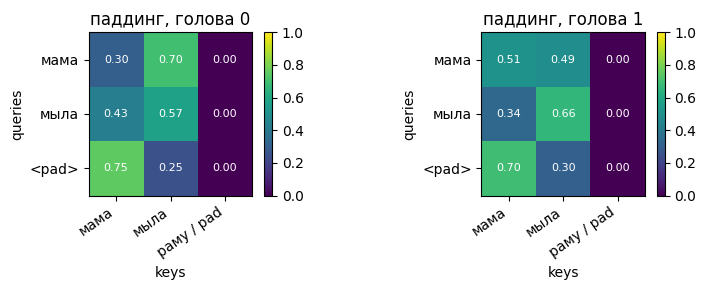

In [59]:
pad_col = attns_pad[0][1, 0, :, 2]
print("предложение 2, голова 0, столбец <pad>:", pad_col.round(decimals=3).tolist())

fig, axes = plt.subplots(1, n_heads, figsize=(8, 3))
for head in range(n_heads):
    plot_attention(attns_pad[0][1, head], labels, ["мама", "мыла", "<pad>"], title=f"паддинг, голова {head}", ax=axes[head])
plt.tight_layout()
plt.show()

## 13. Cross-attention тем же классом

В энкодере Q, K и V из одного предложения, матрица квадратная.

В cross-attention запрос из другой последовательности, ключи и значения из выхода энкодера. В коде это аргумент `context`. Новый класс не нужен.

Возьмём два случайных вектора как «состояние декодера». Они не обучены, это только форма. Строк будет 2, столбцов 3: каждый токен декодера смотрит на все токены энкодера.

В старом seq2seq весь вход сжимали в один вектор. Здесь сжатия нет: декодер достаёт любой токен энкодера.

Среднее внимание декодера: запрос снизу, ключи и значения сбоку, из энкодера. В коде это `context`.

<img src="docs/figures/cross_attention.png" alt="Cross-attention" width="560">


In [ ]:
enc, _ = model(ids)          # [1, 3, 8]
dec = torch.randn(1, 2, d_model)

cross = MultiHeadAttention(d_model, n_heads)
y, w = cross(dec, context=enc, need_weights=True)

print("запросы декодера:", tuple(dec.shape))
print("ключи энкодера:  ", tuple(enc.shape))
print("выход:           ", tuple(y.shape))
print("веса:            ", tuple(w.shape), "  # heads, 2 запроса, 3 ключа")

fig, axes = plt.subplots(1, n_heads, figsize=(8, 3))
for head in range(n_heads):
    plot_attention(w[0, head], tokens, ["dec 0", "dec 1"], title=f"cross, голова {head}", ax=axes[head])
plt.tight_layout()
plt.show()

Полный декодер сегодня не собираем. Это тот же `EncoderBlock`, только внимание внутри другое:

- первое attention — self, с causal-маской с прошлого семинара, в будущее смотреть нельзя;
- второе — cross, `context` равен выходу энкодера;
- потом тот же FFN и те же Add & Norm.

Маска будущего к cross-attention не относится. Будущее закрывают у self-attention декодера.

Блок декодера целиком. Снизу masked self-attention, посередине обычное multi-head, куда сбоку приходит энкодер, сверху тот же FFN.

<img src="docs/figures/decoder_block.png" alt="Блок декодера" width="280">

Вся модель из лекции. Сегодня собрали левую колонку без softmax сверху. Правая колонка устроена из тех же деталей.

<img src="docs/figures/architecture.png" alt="Архитектура трансформера" width="720">
